# Module 3: Machine Learning for Classification (Churn Prediction)

**Project Goal:** Telco Customer Churn ডেটাসেট ব্যবহার করে কোন কাস্টমার সার্ভিস ছেড়ে চলে যাবে (Churn করবে) তা Logistic Regression মডেলের সাহায্যে প্রেডিক্ট করা।

# 3.2 — Data Preparation

এই ধাপে আমরা ডেটাসেটটি লোড করব, কলামের নাম ও টেক্সট ভ্যালুগুলোকে একরকম (uniform) করব, `totalcharges` কলামের ডেটা টাইপ ঠিক করব এবং টার্গেট ভ্যারিয়েবল `churn`-কে সংখ্যায় (0/1) রূপান্তর করব।

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ডেটাসেট ফাইল পড়া
df = pd.read_csv('data-week-3.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


অনেক কলাম থাকলে মাঝের কলামগুলো `...` দিয়ে লুকানো থাকে। তাই `.T` (Transpose) করে নিলে সবগুলো কলামের ভ্যালু একসাথে দেখা সহজ হয়।

In [58]:
print("Shape:", df.shape)
df.head().T

Shape: (7043, 21)


,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


### ১. Column Name ও Text Value একরকম (Uniform) করা
সব কলামের নাম এবং টেক্সট ভ্যালুগুলোকে ছোট হাতের অক্ষর (lowercase) করব এবং ফাঁকা জায়গায় (space) আন্ডারস্কোর (`_`) বসাব।

In [59]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

### ২. `totalcharges` কলামকে Numeric-এ রূপান্তর
`df.dtypes` চেক করলে দেখা যায় `totalcharges` কলামটি `object` (string) হিসেবে আছে। কারণ নতুন কাস্টমারদের ক্ষেত্রে কিছু ভ্যালু ফাঁকা (space) ছিল, যা আগের ধাপে `_` হয়ে গেছে।

`errors='coerce'` ব্যবহার করলে সংখ্যা নয় এমন ভ্যালুগুলো `NaN` (missing value) হয়ে যাবে। এরপর সেগুলোকে আমরা `0` দিয়ে পূরণ করে দেব।

In [60]:
# সংখ্যায় রূপান্তর করা (invalid ভ্যালুগুলো NaN হবে)
tc = pd.to_numeric(df['totalcharges'], errors='coerce')
print("Missing values in totalcharges:", tc.isnull().sum())

# Missing ভ্যালুগুলোকে 0 দিয়ে পূরণ করা
df['totalcharges'] = tc.fillna(0)

Missing values in totalcharges: 11


### ৩. Target Variable `churn`-কে Numeric করা
মেশিন লার্নিং মডেলের জন্য `yes`/`no` ভ্যালুকে `1` এবং `0`-তে রূপান্তর করতে হবে।

In [61]:
df['churn'] = (df['churn'] == 'yes').astype(int)
df['churn'].head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

---
# 3.3 — Setting Up the Validation Framework

Scikit-Learn-এর `train_test_split` ব্যবহার করে ডেটাসেটকে ৩ ভাগে ভাগ করব: **60% Train, 20% Validation, এবং 20% Test**।

1. প্রথমে 20% `test` ডেটা আলাদা করব (বাকি থাকবে 80% `df_full_train`)।
2. এরপর ঐ 80%-এর 25% (যা মূল ডেটার 20%) নেব `validation` সেটের জন্য।

In [62]:
from sklearn.model_selection import train_test_split

# ধাপ ১: Full Train (80%) এবং Test (20%)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

# ধাপ ২: Train (60%) এবং Validation (20%)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print("Dataset sizes (Train, Val, Test):", len(df_train), len(df_val), len(df_test))

Dataset sizes (Train, Val, Test): 4225 1409 1409


এবার ইন্ডেক্সগুলো রিসেট করে নেব এবং মূল ফিচার ডেটাফ্রেম থেকে টার্গেট ভ্যারিয়েবল `churn` আলাদা করে মুছে ফেলব, যাতে **Target Leakage** না হয় (তবে `df_full_train`-এ `churn` রেখে দেব পরের ধাপে EDA করার জন্য)।

In [63]:
# Index reset করা
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# Target ভ্যারিয়েবল আলাদা করা
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

# Feature DataFrame থেকে target মুছে ফেলা
del df_train['churn']
del df_val['churn']
del df_test['churn']

---
# 3.4 — EDA (Exploratory Data Analysis)

EDA করার জন্য আমরা সবসময় `df_full_train` ব্যবহার করব।

In [64]:
# ১. Missing value চেক করা
print(df_full_train.isnull().sum())

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64


### ২. Churn Rate হিসাব করা
যেহেতু `churn` কলামে শুধু `0` এবং `1` আছে, তাই এই কলামের গড় (`mean()`) বের করলেই মোট কত শতাংশ কাস্টমার Churn করেছে (1-এর অনুপাত) তা পাওয়া যায়।

$$
\text{mean} = \frac{\text{number of 1s}}{\text{total rows}} = \text{churn rate}
$$

In [65]:
print(df_full_train['churn'].value_counts(normalize=True)) # normalize=True দিলে value_counts() শুধু count না দিয়ে total rows-এর অনুপাতে fraction দেখায়।

global_churn = df_full_train['churn'].mean()
print("Global Churn Rate:", round(global_churn, 3))

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64
Global Churn Rate: 0.27


অর্থাৎ পুরো ডেটাসেটে গড়ে প্রায় **27%** কাস্টমার সার্ভিস ছেড়ে চলে গেছে।

### ৩. Numerical ও Categorical কলাম আলাদা করা
`customerid` শুধুই একটি আইডি, তাই এটি বাদ যাবে। আর `seniorcitizen` সংখ্যায় (0/1) থাকলেও এটি আসলে একটি ক্যাটাগরি।

In [66]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender', 'seniorcitizen', 'partner', 'dependents',
    'phoneservice', 'multiplelines', 'internetservice',
    'onlinesecurity', 'onlinebackup', 'deviceprotection',
    'techsupport', 'streamingtv', 'streamingmovies',
    'contract', 'paperlessbilling', 'paymentmethod'
]

# কোন ক্যাটাগরিক্যাল কলামে কয়টি ইউনিক ভ্যালু আছে তা দেখা
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

---
# 3.5 — Feature Importance: Churn Rate & Risk Ratio

কোনো নির্দিষ্ট ক্যাটাগরির কাস্টমারদের Churn করার প্রবণতা কেমন, তা আমরা দুটি মাপকাঠি দিয়ে বুঝব:
1. **Difference (`diff`):** $\text{Group Churn Rate} - \text{Global Churn Rate}$
   * `diff > 0` হলে এই গ্রুপের কাস্টমাররা গড়ের চেয়ে **বেশি** Churn করে।
   * `diff < 0` হলে গড়ের চেয়ে **কম** Churn করে।
2. **Risk Ratio (`risk`):** $\frac{\text{Group Churn Rate}}{\text{Global Churn Rate}}$
   * `risk > 1` হলে গড়ের চেয়ে বেশি ঝুঁকিপূর্ণ (High Risk)।
   * `risk < 1` হলে কম ঝুঁকিপূর্ণ (Low Risk)।

In [67]:
from IPython.display import display

# সবগুলো Categorical ফিচারের জন্য লুপ চালিয়ে Churn Rate, Diff এবং Risk দেখা
for c in categorical:
    print("Feature:", c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    display(df_group)
    print()

Feature: gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980



Feature: seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208



Feature: partner


...

,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730



Feature: paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560



Feature: paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


---
# 3.6 — Feature Importance: Mutual Information

**Mutual Information (MI)** আমাদের বলে যে, একটি ক্যাটাগরিক্যাল ফিচারের ভ্যালু জানলে টার্গেট (`churn`) সম্পর্কে আমাদের অনিশ্চয়তা (uncertainty) কতটুকু কমে। অর্থাৎ, কোন ফিচারটি সবচেয়ে বেশি গুরুত্বপূর্ণ তথ্য দেয় তা একই স্কেলে র‍্যাংকিং করার জন্য এটি ব্যবহার করা হয়।
* **High MI:** ফিচারটি খুবই গুরুত্বপূর্ণ।
* **Low MI (প্রায় 0):** ফিচারটির সাথে টার্গেটের তেমন কোনো সম্পর্ক নেই।

In [68]:
from sklearn.metrics import mutual_info_score

def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

# সবগুলো ক্যাটাগরিক্যাল ফিচারের MI বের করে বড় থেকে ছোট ক্রমে সাজানো
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

**ফলাফল:** এখানে দেখা যাচ্ছে `contract`, `onlinesecurity`, এবং `techsupport` সবচেয়ে গুরুত্বপূর্ণ ফিচার। অন্যদিকে `gender` এবং `phoneservice`-এর গুরুত্ব প্রায় শূন্য।

---
# 3.7 — Feature Importance: Correlation

সংখ্যাবাচক (Numerical) ফিচারগুলোর সাথে টার্গেট `churn`-এর সম্পর্ক বোঝার জন্য আমরা **Correlation Coefficient** ব্যবহার করি।
* **Positive Correlation:** ফিচারের মান বাড়লে Churn হওয়ার সম্ভাবনা বাড়ে।
* **Negative Correlation:** ফিচারের মান বাড়লে Churn হওয়ার সম্ভাবনা কমে।

In [69]:
# প্রতিটি Numerical ফিচারের সাথে churn-এর correlation
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

* `tenure` (-0.35): কাস্টমার যত বেশি মাস ধরে কোম্পানিতে আছে, তার চলে যাওয়ার সম্ভাবনা তত কম (সবচেয়ে শক্তিশালী সম্পর্ক)।
* `monthlycharges` (+0.19): মাসিক বিল যত বেশি, চলে যাওয়ার সম্ভাবনা তত বেশি।

নিচে গ্রুপ করে এর বাস্তব প্রমাণ দেখা যাক:

In [70]:
print('Tenure <= 2 months:', round(df_full_train[df_full_train.tenure <= 2].churn.mean(), 3))
print('Tenure 3-12 months:', round(df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean(), 3))
print('Tenure > 12 months:', round(df_full_train[df_full_train.tenure > 12].churn.mean(), 3))
print('-' * 40)
print('Monthly charges <= $20:', round(df_full_train[df_full_train.monthlycharges <= 20].churn.mean(), 3))
print('Monthly charges $21-$50:', round(df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean(), 3))
print('Monthly charges > $50:', round(df_full_train[df_full_train.monthlycharges > 50].churn.mean(), 3))

Tenure <= 2 months: 0.595
Tenure 3-12 months: 0.399
Tenure > 12 months: 0.176
----------------------------------------
Monthly charges <= $20: 0.088
Monthly charges $21-$50: 0.183
Monthly charges > $50: 0.325


---
# 3.8 — One-Hot Encoding (using `DictVectorizer`)

মেশিন লার্নিং মডেল টেক্সট বোঝে না, তাই ক্যাটাগরিক্যাল কলামগুলোকে 0 এবং 1-এ রূপান্তর (One-Hot Encoding) করতে হবে। Scikit-Learn-এর `DictVectorizer` খুব সহজে এই কাজটি করে দেয়।

### কাজের ধাপ:
1. **`to_dict(orient='records')`:** ডেটাফ্রেমের প্রতিটি রো (row)-কে একেকটি ডিকশনারিতে রূপান্তর করে লিস্ট বানানো হয়, কারণ `DictVectorizer` ইনপুট হিসেবে ডিকশনারির লিস্ট নেয়।
2. **`DictVectorizer(sparse=False)`:** সাধারণ NumPy Array (Dense Matrix) পাওয়ার জন্য `sparse=False` দেওয়া হয়। (বড় ডেটাসেটে মেমোরি বাঁচাতে ডিফল্ট `sparse=True` ব্যবহৃত হয়, যা শুধু অশূন্য মানগুলোর পজিশন সেভ রাখে)।
3. **`fit_transform(train_dict)`:** ট্রেইনিং ডেটা থেকে ক্যাটাগরিগুলো শেখে (`fit`) এবং সেগুলোকে সংখ্যার ম্যাট্রিক্সে রূপান্তর করে (`transform`)। সংখ্যার কলামগুলো (যেমন: `tenure`) অপরিবর্তিত থাকে।
4. **`transform(val_dict)`:** ভ্যালিডেশন ডেটায় আমরা শুধু `transform` ব্যবহার করি (`fit` করি না), যাতে ট্রেইনিং এবং ভ্যালিডেশন সেটের কলামের সংখ্যা ও সিরিয়াল হুবহু এক থাকে।

In [ ]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler

# ১. Numerical ফিচারগুলোকে Scale করা
scaler = StandardScaler()

df_train_scaled = df_train.copy()
df_val_scaled = df_val.copy()

# Train ডেটায় fit_transform এবং Validation ডেটায় শুধু transform করব
df_train_scaled[numerical] = scaler.fit_transform(df_train[numerical])
df_val_scaled[numerical] = scaler.transform(df_val[numerical])

# ২. DictVectorizer দিয়ে এনকোড করা
dv = DictVectorizer(sparse=False)

# 3. Training Data এনকোড করা
train_dict = df_train_scaled[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

# 4. Validation Data এনকোড করা
val_dict = df_val_scaled[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

print("X_train shape:", X_train.shape)
print("Feature names:\n", dv.get_feature_names_out()[:10]) # প্রথম ১০টি কলামের নাম

X_train shape: (4225, 45)
Feature names:
 ['contract=month-to-month' 'contract=one_year' 'contract=two_year'
 'dependents=no' 'dependents=yes' 'deviceprotection=no'
 'deviceprotection=no_internet_service' 'deviceprotection=yes'
 'gender=female' 'gender=male']


---
# 3.9 — Logistic Regression

**Binary Classification** সমস্যার (যেখানে টার্গেট 0 অথবা 1) সমাধানের জন্য **Logistic Regression** ব্যবহার করা হয়।

* **Linear Regression** যেকোনো বাস্তব সংখ্যা আউটপুট দেয়: $z = w_0 + w_1x_1 + w_2x_2 + ... + w_nx_n$
* কিন্তু আমাদের দরকার **Probability** (সম্ভাবনা), যা সবসময় `0` থেকে `1`-এর মধ্যে থাকে। তাই Logistic Regression-এ ঐ Linear score ($z$)-কে **Sigmoid Function**-এর ভেতর দিয়ে পাস করা হয়:

$$\text{Sigmoid}(z) = \frac{1}{1 + \exp(-z)}$$

* Score ($z$) অনেক বড় পজিটিভ হলে আউটপুট `1`-এর কাছাকাছি হবে।
* Score ($z$) অনেক বড় নেগেটিভ হলে আউটপুট `0`-এর কাছাকাছি হবে।
* Score `0` হলে আউটপুট হবে `0.5` (50% সম্ভাবনা)।

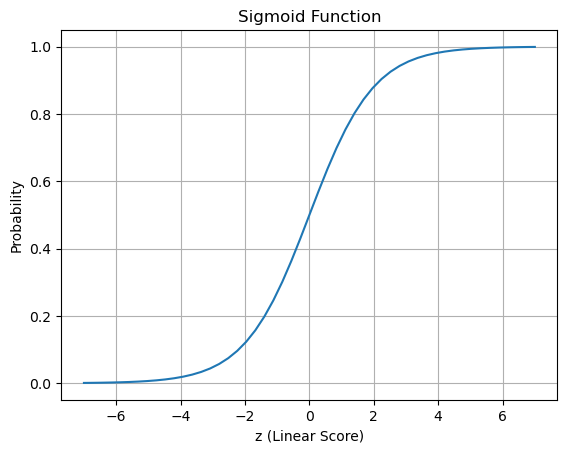

In [72]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Sigmoid কার্ভ প্লট করে দেখা
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))
plt.title("Sigmoid Function")
plt.xlabel("z (Linear Score)")
plt.ylabel("Probability")
plt.grid(True)
plt.show()

### কোডে Linear বনাম Logistic Regression-এর পার্থক্য:

In [73]:
def linear_regression(xi, w0, w):
    result = w0
    for j in range(len(w)):
        result = result + xi[j] * w[j]
    return result

def logistic_regression(xi, w0, w):
    score = w0
    for j in range(len(w)):
        score = score + xi[j] * w[j]
    return sigmoid(score)  # শুধুমাত্র শেষে sigmoid যোগ করা হয়েছে

---
# 3.10 — Training Logistic Regression with Scikit-Learn

এবার আমরা Scikit-Learn ব্যবহার করে আমাদের এনকোড করা ডেটার ওপর মডেল ট্রেইন করব।
* **`model.intercept_[0]`:** Bias বা বেসলাইন ($w_0$)।
* **`model.coef_[0]`:** প্রতিটি ফিচারের গুরুত্ব বা Weights ($w$)।
* **`model.predict(X)`:** সরাসরি 0 বা 1 উত্তর দেয় (Hard Predictions)।
* **`model.predict_proba(X)`:** Probability বা সম্ভাবনা রিটার্ন করে (Soft Predictions)। এর প্রথম কলামটি Class 0 এবং দ্বিতীয় কলামটি `[:, 1]` হলো Class 1 (Churn হওয়ার সম্ভাবনা)।
* **`solver='lbfgs'`:** এটি একটি অপটিমাইজেশন অ্যালগরিদম যা সবচেয়ে ভালো weights ($w$) খুঁজে বের করতে সাহায্য করে।

In [74]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='lbfgs', max_iter=1000)
model.fit(X_train, y_train)

print("Bias (w0):", round(model.intercept_[0], 3))
print("First 10 Weights:", model.coef_[0].round(3)[:10])

Bias (w0): -0.557
First 10 Weights: [ 0.584 -0.072 -0.793 -0.105 -0.175  0.002 -0.231 -0.052 -0.121 -0.16 ]


### Validation ডেটায় প্রেডিকশন এবং Accuracy নির্ণয়
যদি Churn হওয়ার সম্ভাবনা 50% (`0.5`) বা তার বেশি হয়, তবে আমরা ধরে নেব কাস্টমারটি Churn করবে।

In [75]:
# Soft prediction (সম্ভাবনা বের করা)
y_pred = model.predict_proba(X_val)[:, 1]

# Threshold 0.5 ধরে সিদ্ধান্ত নেওয়া
churn_decision = (y_pred >= 0.5)

# আসল ভ্যালুর সাথে মিলিয়ে Accuracy বের করা
accuracy = (y_val == churn_decision).mean()
print("Validation Accuracy:", round(accuracy, 4))

Validation Accuracy: 0.8062


In [76]:
# একটি টেবিলের মাধ্যমে প্রেডিকশন ও আসল ফলাফল পাশাপাশি দেখা
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val
df_pred['correct'] = df_pred.prediction == df_pred.actual

df_pred.head()

,probability,prediction,actual,correct
0,0.006978,0,0,True
1,0.203284,0,0,True
2,0.215640,0,0,True
3,0.563822,1,1,True
4,0.214859,0,0,True


---
# 3.11 — Model Interpretation

মডেলটি কীভাবে সিদ্ধান্ত নিচ্ছে তা বোঝার জন্য আমরা `zip()` ফাংশন দিয়ে প্রতিটি ফিচারের নামের সাথে তার Weight ($w$)-কে জোড়া লাগিয়ে দেখব।

In [81]:
# zip() ফাংশন কীভাবে কাজ করে তার একটি উদাহরণ
a = [1, 2, 3, 4]
b = 'abcd'
dict(zip(a, b))

{1: 'a', 2: 'b', 3: 'c', 4: 'd'}

In [77]:
# ৪৫টি ফিচারের নাম এবং তাদের Weight
feature_weights = dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

# বোঝার সুবিধার্থে শুধু ৩টি গুরুত্বপূর্ণ ফিচার নিয়ে একটি ছোট মডেল তৈরি করা
small = ['contract', 'tenure', 'monthlycharges']

dicts_train_small = df_train[small].to_dict(orient='records')
dv_small = DictVectorizer(sparse=False)
X_train_small = dv_small.fit_transform(dicts_train_small)

model_small = LogisticRegression(solver='lbfgs')
model_small.fit(X_train_small, y_train)

w0 = model_small.intercept_[0]
w = model_small.coef_[0]

print("Small Model Bias (w0):", round(w0, 3))
print("Small Model Weights:")
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

Small Model Bias (w0): -2.478
Small Model Weights:


{'contract=month-to-month': np.float64(0.971),
 'contract=one_year': np.float64(-0.024),
 'contract=two_year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

### Weight দেখে ব্যাখ্যা:
* **Positive Weight:** Churn হওয়ার সম্ভাবনা বাড়িয়ে দেয় (যেমন: `contract=month-to-month` এর ওয়েট `+0.97` এবং `monthlycharges` `+0.027`)।
* **Negative Weight:** Churn হওয়ার সম্ভাবনা কমিয়ে দেয় (যেমন: `contract=two_year` এর ওয়েট `-0.949` এবং `tenure` `-0.036`)।

### ম্যানুয়ালি একজন কাস্টমারের Churn Probability হিসাব করা:
ধরো, একজন কাস্টমারের কনট্র্যাক্ট `two_year` (তাই শুধু এই ক্যাটাগরিটি `1` হবে, বাকি কনট্র্যাক্ট ক্যাটাগরি `0`), মাসিক বিল `$30`, এবং সে `24` মাস ধরে আছে।

In [78]:
score = -2.47 + (-0.949 * 1) + (30 * 0.027) + (24 * -0.036)
prob = sigmoid(score)

print("Manual Score:", round(score, 3))
print("Churn Probability:", round(prob, 4))

Manual Score: -3.473
Churn Probability: 0.0301


তার চলে যাওয়ার সম্ভাবনা মাত্র **3%** (কারণ Score নেগেটিভ)। মনে রাখবে, Score পজিটিভ হলে সম্ভাবনা 50%-এর বেশি হয়, আর নেগেটিভ হলে 50%-এর কম হয়।

---
# 3.12 — Using the Model (Final Training & Testing)

আমাদের পরীক্ষা-নিরীক্ষা শেষ। এখন চূড়ান্ত মডেল তৈরির পালা:
1. `df_full_train` (Train + Validation = 80% ডেটা) ব্যবহার করে নতুন `DictVectorizer` এবং `LogisticRegression` মডেল ট্রেইন করব।
2. সম্পূর্ণ অদেখা `df_test` (20% ডেটা)-এর ওপর মডেলটি পরীক্ষা করব।

In [79]:
# ১. Full Training ও Test ডেটার Numerical কলাম Scale করা
scaler_full = StandardScaler()

df_full_train_scaled = df_full_train.copy()
df_test_scaled = df_test.copy()

df_full_train_scaled[numerical] = scaler_full.fit_transform(df_full_train[numerical])
df_test_scaled[numerical] = scaler_full.transform(df_test[numerical])

# ২. Full Training Data এনকোড ও মডেল ট্রেইন করা
dicts_full_train = df_full_train_scaled[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)
y_full_train = df_full_train.churn.values

model = LogisticRegression(solver='lbfgs')
model.fit(X_full_train, y_full_train)

# ৩. Test Set দিয়ে মডেলের চূড়ান্ত পারফরম্যান্স চেক করা
dicts_test = df_test_scaled[categorical + numerical].to_dict(orient='records')
X_test = dv.transform(dicts_test)

y_pred = model.predict_proba(X_test)[:, 1]
churn_decision = (y_pred >= 0.5)

print("Test Set Accuracy:", round((churn_decision == y_test).mean(), 4))

Test Set Accuracy: 0.8112


Validation Accuracy ছিল প্রায় **80.3%** এবং Test Accuracy এসেছে প্রায় **81.5%**। দুটি ফলাফলই খুব কাছাকাছি, অর্থাৎ আমাদের মডেলে কোনো **Overfitting** হয়নি এবং এটি নতুন ডেটায় চমৎকার কাজ করছে।

### বাস্তবে একজন একক কাস্টমারের ওপর মডেলের ব্যবহার:
প্রোডাকশনে পুরো ডেটাসেট একসাথে না এসে একজন কাস্টমারের তথ্য একটি ডিকশনারি হিসেবে আসে।

In [80]:
# টেস্ট সেটের শেষ কাস্টমারের আসল (Unscaled) ডেটা নেওয়া
raw_customer = df_test[categorical + numerical].iloc[-1:].copy()

# ১. আগে Numerical কলামগুলো স্কেল করা
raw_customer[numerical] = scaler_full.transform(raw_customer[numerical])

# ২. ডিকশনারিতে রূপান্তর এবং ট্রান্সফর্ম করা
customer_dict = raw_customer.to_dict(orient='records')
X_small = dv.transform(customer_dict)

# ৩. Churn হওয়ার সম্ভাবনা বের করা
prob = model.predict_proba(X_small)[0, 1]
print("Predicted Churn Probability:", round(prob, 4))
print("Actual Status in Test Set:", y_test[-1])

Predicted Churn Probability: 0.6388
Actual Status in Test Set: 1


মডেল বলছে এই কাস্টমারের চলে যাওয়ার সম্ভাবনা প্রায় **60%**, যা 0.5-এর বেশি। এবং আসল ডেটাতেও দেখা যাচ্ছে কাস্টমারটি সত্যিই চলে গিয়েছিল (`1`)। বাস্তবে এই ধরনের কাস্টমারদের ধরে রাখার জন্য কোম্পানি ডিসকাউন্ট বা প্রমোশনাল অফার পাঠিয়ে থাকে।